# GRU — ajuste de umbral e iteración post-baseline

Este notebook parte del baseline v0 congelado (`notebooks/gru/gru_model_training.ipynb`, ver `docs/gru/adr/0003-gru-early-stopping-criterion.md`) **sin reentrenar nada** — usa el modelo ya guardado (`models/gru/baseline_w10.keras`) y solo ajusta el umbral de decisión sobre sus probabilidades de salida.

In [1]:
import sys
sys.path.append("../..")  # raíz del repo, para poder importar src.*

import json
import os

import numpy as np
import pandas as pd
import tensorflow as tf

from src.models.gru.threshold import (
    plot_threshold_strategies,
    select_threshold_strategies,
    sweep_thresholds,
)
from src.models.gru.train import evaluate_gru_model

np.random.seed(42)
tf.random.set_seed(42)

In [2]:
MODEL_PATH = "../../models/gru/baseline_w10.keras"
model = tf.keras.models.load_model(MODEL_PATH)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 10, 63)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 32)             │         9,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,037 (109.52 KB)

 Trainable params: 9,345 (36.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 18,692 (73.02 KB)

In [3]:
DATA_DIR = "../../data/sequences"
W = 10

# Solo validación en este notebook: la elección de umbral es un ajuste de
# hiperparámetro y debe hacerse sobre val. X_test/y_test no se tocan aquí.
X_val = np.load(f"{DATA_DIR}/X_val_w{W}.npy")
y_val = np.load(f"{DATA_DIR}/y_val_w{W}.npy")

print(f"X_val: {X_val.shape} {X_val.dtype} | y_val: {y_val.shape} {y_val.dtype}")

X_val: (67513, 10, 63) float32 | y_val: (67513,) int8


In [4]:
df_umbrales = sweep_thresholds(model, X_val, y_val)
print("df_umbrales.shape:", df_umbrales.shape)

df_umbrales.shape: (999, 9)


In [5]:
estrategias = select_threshold_strategies(df_umbrales)
pd.DataFrame(estrategias).T

,threshold,precision,recall,f1,f2,tn,fp,fn,tp
f1_maximo,0.337,0.993377,0.995733,0.994554,0.995261,65390.0,14.0,9.0,2100.0
f2_maximo,0.050,0.985507,0.999526,0.992467,0.996690,65373.0,31.0,1.0,2108.0
recall_min_0.90,0.938,0.998541,0.973447,0.985834,0.978364,65401.0,3.0,56.0,2053.0
recall_min_0.95,0.938,0.998541,0.973447,0.985834,0.978364,65401.0,3.0,56.0,2053.0
recall_min_0.97,0.938,0.998541,0.973447,0.985834,0.978364,65401.0,3.0,56.0,2053.0
costo_5x,0.050,0.985507,0.999526,0.992467,0.996690,65373.0,31.0,1.0,2108.0
costo_10x,0.050,0.985507,0.999526,0.992467,0.996690,65373.0,31.0,1.0,2108.0
costo_20x,0.050,0.985507,0.999526,0.992467,0.996690,65373.0,31.0,1.0,2108.0


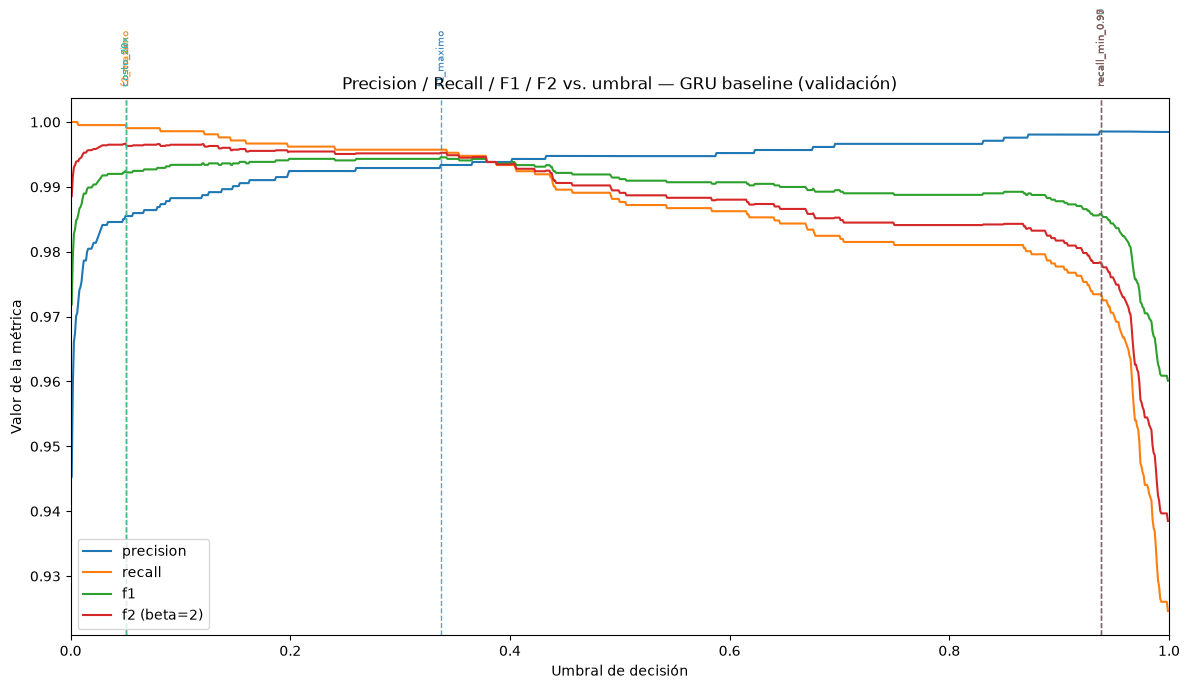

In [6]:
fig = plot_threshold_strategies(df_umbrales, estrategias)

Estrategias guardadas en: ../../results/gru/threshold_strategies_w10.json
Gráfica guardada en: ../../results/gru/threshold_strategies_w10.png


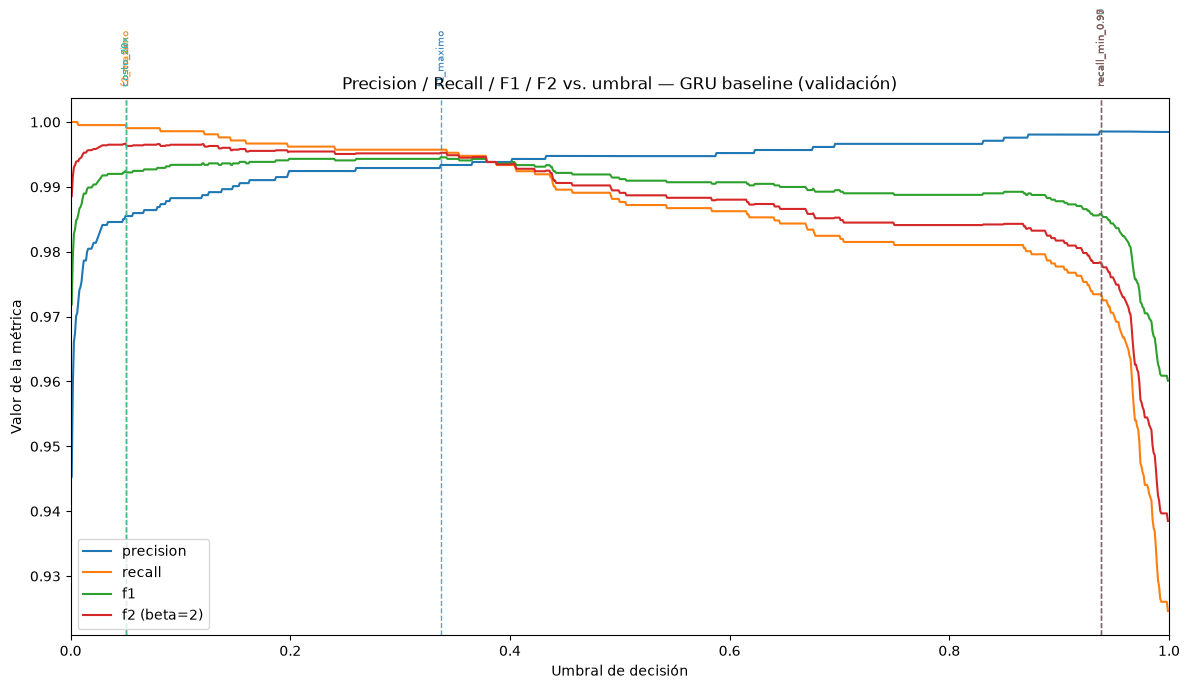

In [7]:
STRATEGIES_PATH = "../../results/gru/threshold_strategies_w10.json"
CURVES_PATH = "../../results/gru/threshold_strategies_w10.png"
os.makedirs(os.path.dirname(STRATEGIES_PATH), exist_ok=True)

with open(STRATEGIES_PATH, "w", encoding="utf-8") as f:
    json.dump(estrategias, f, indent=2, ensure_ascii=False)
print(f"Estrategias guardadas en: {STRATEGIES_PATH}")

plot_threshold_strategies(df_umbrales, estrategias, save_path=CURVES_PATH)
print(f"Gráfica guardada en: {CURVES_PATH}")

## Evaluación final en test — umbral elegido: 0.050 (estrategia F2/costo, ver ADR 0005)

In [8]:
X_test = np.load("../../data/sequences/X_test_w10.npy")
y_test = np.load("../../data/sequences/y_test_w10.npy")
print(f"X_test: {X_test.shape} | y_test: {y_test.shape}")

X_test: (67512, 10, 63) | y_test: (67512,)


In [9]:
UMBRAL_ELEGIDO = 0.050
metricas_test_ajustado = evaluate_gru_model(model, X_test, y_test, threshold=UMBRAL_ELEGIDO)

print(f"=== Resultados en test — umbral ajustado ({UMBRAL_ELEGIDO}) ===")
print(f"Accuracy:  {metricas_test_ajustado['accuracy']:.4f}")
print(f"Precision: {metricas_test_ajustado['precision']:.4f}")
print(f"Recall:    {metricas_test_ajustado['recall']:.4f}  <- métrica principal")
print(f"F1-score:  {metricas_test_ajustado['f1']:.4f}")
print(f"ROC-AUC:   {metricas_test_ajustado['roc_auc']:.4f}")
print(f"Matriz de confusión [[tn, fp], [fn, tp]]: {metricas_test_ajustado['confusion_matrix']}")
print()
print(metricas_test_ajustado["classification_report"])

=== Resultados en test — umbral ajustado (0.05) ===
Accuracy:  0.9973
Precision: 0.9555
Recall:    0.8758  <- métrica principal
F1-score:  0.9139
ROC-AUC:   0.9996
Matriz de confusión [[tn, fp], [fn, tp]]: [[66364, 45], [137, 966]]

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     66409
           1       0.96      0.88      0.91      1103

    accuracy                           1.00     67512
   macro avg       0.98      0.94      0.96     67512
weighted avg       1.00      1.00      1.00     67512



In [ ]:
import json
RESULTS_PATH = "../../results/gru/baseline_w10_threshold_tuned_metrics.json"
os.makedirs(os.path.dirname(RESULTS_PATH), exist_ok=True)

resumen = {
    "modelo": "GRU_baseline_w10_umbral_ajustado",
    "umbral_elegido": UMBRAL_ELEGIDO,
    "criterio_seleccion": "f2_maximo (equivalente a costo_5x/10x/20x, ver ADR 0005)",
    "accuracy": metricas_test_ajustado["accuracy"],
    "precision": metricas_test_ajustado["precision"],
    "recall": metricas_test_ajustado["recall"],
    "f1": metricas_test_ajustado["f1"],
    "roc_auc": metricas_test_ajustado["roc_auc"],
    "confusion_matrix": metricas_test_ajustado["confusion_matrix"],
    "comparacion_umbral_0.5_sin_ajustar": {
        "nota": "Ver docs/gru/adr/0003-gru-early-stopping-criterion.md y "
                "docs/gru/adr/0005-ajuste-umbral-decision-gru.md para comparación completa"
    },
}

with open(RESULTS_PATH, "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False)
print(f"Métricas guardadas en: {RESULTS_PATH}")

Umbral elegido: 0.050 (estrategia F2/costo). Ver `docs/gru/adr/0005-ajuste-umbral-decision-gru.md` para el análisis completo de las 8 estrategias comparadas y la justificación de la elección.